# Metrical BDI Analysis

This notebook performs authorship verification on metrical patterns using the BDI (Bootstrap Distance Imposters) algorithm from the [`bdi`](https://github.com/bnagy/bdi) package.

**Pipeline:**
1. Load metrical pattern data from CSV
2. Scale features (StandardScaler)
3. Run BDI verification with `minmax` metric (no feature selection)
4. Compare feature selection variants

In [48]:
import sys
from pathlib import Path
import joblib

sys.path.insert(0, "/Users/ben/code/bdi")

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import logging

import pandas as pd
import numpy as np

from sklearn.preprocessing import StandardScaler, LabelEncoder

from bdi import BDIVerifier

logging.basicConfig(level="INFO")
logger = logging.getLogger("bdi")

import mpl_fontkit as fk

fk.install("Roboto Condensed")

Font name: `Roboto Condensed`


## Loading the data

In [50]:
def find_metrical_root():
    current = Path.cwd().resolve()

    for folder in [current, *current.parents]:
        required = [
            folder / "output.csv",
            folder / "metrical_scaler.pkl",
            folder / "metrical_bdi_calibration_model.pkl",
        ]
        if all(path.exists() for path in required):
            return folder

    raise FileNotFoundError(
        "Could not find the Metrical analysis root containing output.csv "
        "and the calibration files."
    )


BASE_DIR = find_metrical_root()

raw_df = pd.read_csv(BASE_DIR / "output.csv", encoding="utf-8")

print(f"Metrical analysis root: {BASE_DIR}")
print(f"Loaded {raw_df.shape[0]} rows, {raw_df.shape[1]} columns")
print(f"Authors: {raw_df['Author'].nunique()} unique")
raw_df.head()

Metrical analysis root: /Users/martinapaccara/Documents/Documenti/Università/DOTTORATO/Lavoro/Digitale/Stilometria/hexameters/Metrical analysis
Loaded 663 rows, 24 columns
Authors: 42 unique


,Author,Work,Poem,1SP,2SP,3SP,4SP,1CF,2CF,3CF,...,4DI,1SC,2SC,3SC,4SC,1WC,2WC,3WC,4WC,ELC
0,AI,anticlaudianus,anticlaudianus - 1,0.380000,0.513333,0.620000,0.666667,0.280000,0.746667,0.820000,...,0.446667,0.360000,0.573333,0.840000,0.613333,0.166667,0.153333,0.160000,0.080000,0.000000
1,AI,anticlaudianus,anticlaudianus - 2,0.386667,0.586667,0.653333,0.813333,0.306667,0.700000,0.826667,...,0.493333,0.340000,0.540000,0.840000,0.633333,0.140000,0.193333,0.146667,0.020000,0.000000
2,AI,anticlaudianus,anticlaudianus - 3,0.293333,0.573333,0.520000,0.746667,0.260000,0.713333,0.886667,...,0.500000,0.326667,0.620000,0.880000,0.633333,0.180000,0.160000,0.100000,0.026667,0.000000
3,AI,anticlaudianus,anticlaudianus - 4,0.440000,0.480000,0.606667,0.820000,0.260000,0.700000,0.886667,...,0.433333,0.393333,0.600000,0.886667,0.660000,0.120000,0.153333,0.106667,0.046667,0.006667
4,AI,anticlaudianus,anticlaudianus - 5,0.353333,0.586667,0.593333,0.780000,0.226667,0.680000,0.846667,...,0.566667,0.380000,0.526667,0.846667,0.580000,0.173333,0.200000,0.133333,0.053333,0.000000


## Factorizing

The BDI code needs numeric labels. We use `LabelEncoder` to convert author names to integers.

In [52]:
print(raw_df["Author"].unique())

<ArrowStringArray>
[ 'AI', 'AeC', 'AeP',  'BC',   'B',  'DC',   'E',  'FB', 'GAp', 'GAr',  'GC',
  'GM',  'GP', 'GVS', 'GiP',  'HA',  'HP',   'H',  'IH',  'II',   'M', 'NLC',
  'OM', 'OSE',  'RC',  'RT',  'SG', 'U10', 'U11',  'U1',  'U2',  'U3',  'U4',
  'U5',  'U6',  'U7',  'U8',  'U9',  'X2',  'X3',  'X4',   'X']
Length: 42, dtype: str


In [53]:
label_encoder = LabelEncoder()
raw_df["author_label"] = label_encoder.fit_transform(
    raw_df["Author"].astype(str)
)

print("Application label encoder fitted on all authors/codes in output.csv.")

Application label encoder fitted on all authors/codes in output.csv.


In [54]:
mapping = (
    raw_df[["Author", "author_label"]]
    .drop_duplicates()
    .sort_values("author_label")
)

print(mapping.to_string(index=False))

Author  author_label
    AI             0
   AeC             1
   AeP             2
     B             3
    BC             4
    DC             5
     E             6
    FB             7
   GAp             8
   GAr             9
    GC            10
    GM            11
    GP            12
   GVS            13
   GiP            14
     H            15
    HA            16
    HP            17
    IH            18
    II            19
     M            20
   NLC            21
    OM            22
   OSE            23
    RC            24
    RT            25
    SG            26
    U1            27
   U10            28
   U11            29
    U2            30
    U3            31
    U4            32
    U5            33
    U6            34
    U7            35
    U8            36
    U9            37
     X            38
    X2            39
    X3            40
    X4            41


## Scaling

Load the scaler fitted during calibration on known-author data only, then transform the full metrical dataset. The four attribution problems (`X`, `X2`, `X3`, `X4`) did not contribute to scaler fitting.


In [56]:
scaler = joblib.load(
    BASE_DIR / "metrical_scaler.pkl"
)

calibration_model = joblib.load(
    BASE_DIR / "metrical_bdi_calibration_model.pkl"
)

if hasattr(scaler, "feature_names_in_"):
    numeric_cols = list(scaler.feature_names_in_)
else:
    numeric_cols = [
        c for c in raw_df.select_dtypes(include=["number"]).columns
        if c != "author_label"
    ]

df_scaled = pd.DataFrame(
    scaler.transform(raw_df[numeric_cols]),
    columns=numeric_cols,
    index=raw_df.index,
)

df_scaled["author_label"] = raw_df["author_label"].values

print(f"Scaled shape: {df_scaled.shape}")
print("Loaded corpus-specific logistic calibration model.")
df_scaled.head()

Scaled shape: (663, 22)
Loaded corpus-specific logistic calibration model.


,1SP,2SP,3SP,4SP,1CF,2CF,3CF,4CF,1DI,2DI,...,1SC,2SC,3SC,4SC,1WC,2WC,3WC,4WC,ELC,author_label
0,3.054783,3.650533,4.954660,4.996508,3.077754,6.298994,5.700973,5.113733,5.879928,0.326442,...,3.734001,6.140150,7.007567,5.818115,3.557436,2.586078,1.998365,2.149261,0.000000,0
1,3.108376,4.172038,5.221039,6.095740,3.370873,5.905307,5.747323,5.407626,6.344133,0.163221,...,3.526557,5.783165,7.007567,6.007837,2.988246,3.260706,1.831835,0.537315,0.000000,0
2,2.358078,4.077219,4.155521,5.596089,2.857914,6.017789,6.164467,5.231290,5.493091,0.285637,...,3.388260,6.639930,7.341261,6.007837,3.842031,2.698516,1.248978,0.716420,0.000000,0
3,3.537118,3.413485,4.848108,6.145705,2.857914,5.905307,6.164467,5.583962,5.570459,0.285637,...,4.079742,6.425738,7.396877,6.260798,2.561354,2.586078,1.332244,1.253735,0.097425,0
4,2.840413,4.172038,4.741556,5.845915,2.491515,5.736584,5.886371,4.702284,5.879928,0.652885,...,3.941446,5.640370,7.063183,5.501913,3.699734,3.373145,1.665304,1.432840,0.000000,0


## Verification (no feature selection)

We hold out *De machabeis* as the problem set and verify against all other authors using the `minmax` metric.

Only the current problem text is removed from the comparison corpus. The other attribution problems remain available as comparison texts and candidates, as in the original notebook.

In [58]:
target_author = "X3"
target_text = "machabeis"

problem_mask = (
    (raw_df["Author"].astype(str) == target_author)
    & (raw_df["Work"].astype(str) == target_text)
)

if problem_mask.sum() == 0:
    raise ValueError(
        f"No rows found for target {target_author}_{target_text}."
    )

# Application stage: remove only the current problem.
# The other uncertain texts remain in the comparison corpus.
comparison_mask = ~problem_mask

problem_X = df_scaled.loc[problem_mask].copy()
comparison_X = df_scaled.loc[comparison_mask].copy()

problem_y = problem_X["author_label"]
comparison_y = comparison_X["author_label"]

problem_X = problem_X.drop(columns=["author_label"])
comparison_X = comparison_X.drop(columns=["author_label"])

print(f"Problem: {problem_X.shape} | Comparison: {comparison_X.shape}")
print(
    f"Comparison authors: "
    f"{sorted(raw_df.loc[comparison_mask, 'Author'].astype(str).unique())}"
)

Problem: (3, 21) | Comparison: (660, 21)
Comparison authors: ['AI', 'AeC', 'AeP', 'B', 'BC', 'DC', 'E', 'FB', 'GAp', 'GAr', 'GC', 'GM', 'GP', 'GVS', 'GiP', 'H', 'HA', 'HP', 'IH', 'II', 'M', 'NLC', 'OM', 'OSE', 'RC', 'RT', 'SG', 'U1', 'U10', 'U11', 'U2', 'U3', 'U4', 'U5', 'U6', 'U7', 'U8', 'U9', 'X', 'X2', 'X4']


In [59]:
rng = np.random.default_rng(42)

# Fit BDI verifier with minmax metric, no feature selection
bdi_mm = BDIVerifier(
    metric="minmax",
    nb_bootstrap_iter=1000,
    rnd_prop=0.35,
    random_state=rng,
)
bdi_mm.fit(comparison_X, comparison_y)

# Verify problem chunks against every candidate author
results = {}
chunk_results = {}

for int_label in sorted(set(comparison_y)):
    str_label = label_encoder.classes_[int_label]
    print(f"...... Testing against: {str_label}")

    try:
        probas = bdi_mm.predict_proba(
            problem_X,
            [int_label] * problem_X.shape[0],
        )

        probas = np.asarray(probas, dtype=float)

        calibrated = calibration_model.predict_proba(
            probas.reshape(-1, 1)
        )[:, 1]

        results[str_label] = {
            "mean": np.mean(probas),
            "std": np.std(probas),
            "calibrated_mean": np.mean(calibrated),
            "calibrated_std": np.std(calibrated),
            "calibrated_median": np.median(calibrated),
        }

        chunk_results[str_label] = pd.DataFrame(
            {
                "match_strength": probas,
                "calibrated_probability": calibrated,
            },
            index=problem_X.index,
        )

        print(
            f"    Match strength: "
            f"{np.mean(probas):.4f} ± {np.std(probas):.4f}"
        )
        print(
            f"    Calibrated P(same author): "
            f"{np.mean(calibrated):.4f} ± {np.std(calibrated):.4f}"
        )

    except Exception as e:
        print(f"    Error: {e}")

09/18/2026 07:07:47 [bdi:INFO] Fitting on 660 documents...
09/18/2026 07:07:47 [bdi:INFO] Predicting on 3 documents


...... Testing against: AI


09/18/2026 07:07:47 [bdi:INFO] Predicting on 3 documents


    Match strength: 0.0113 ± 0.0074
    Calibrated P(same author): 0.0113 ± 0.0006
...... Testing against: AeC


09/18/2026 07:07:47 [bdi:INFO] Predicting on 3 documents


...

    Match strength: 0.0040 ± 0.0033
    Calibrated P(same author): 0.0106 ± 0.0003
...... Testing against: U9


09/18/2026 07:07:51 [bdi:INFO] Predicting on 3 documents


    Match strength: 0.0497 ± 0.0025
    Calibrated P(same author): 0.0151 ± 0.0003
...... Testing against: X


09/18/2026 07:07:51 [bdi:INFO] Predicting on 3 documents
09/18/2026 07:07:51 [bdi:INFO] Predicting on 3 documents


    Match strength: 0.1063 ± 0.0529
    Calibrated P(same author): 0.0248 ± 0.0087
...... Testing against: X2
    Match strength: 0.1143 ± 0.0381
    Calibrated P(same author): 0.0255 ± 0.0065
...... Testing against: X4
    Match strength: 0.5467 ± 0.0773
    Calibrated P(same author): 0.4193 ± 0.1399


In [60]:
summary = pd.DataFrame(results).T
summary = summary.sort_values("calibrated_mean", ascending=False)

summary.columns = [
    "Match Strength (mean)",
    "Match Strength (std)",
    "Calibrated Probability (mean)",
    "Calibrated Probability (std)",
    "Calibrated Probability (median)",
]

summary.index.name = "Candidate"

summary = summary.round(4)

display(summary)

summary.to_csv("metrical_bdi_candidate_summary.csv")

,Match Strength (mean),Match Strength (std),Calibrated Probability (mean),Calibrated Probability (std),Calibrated Probability (median)
Candidate,,,,,
U11,0.9280,0.0067,0.9299,0.0034,0.9309
M,0.7917,0.0349,0.8195,0.0369,0.7959
HA,0.7887,0.0502,0.8124,0.0595,0.8298
B,0.6170,0.1406,0.5438,0.2391,0.6129
H,0.5580,0.0936,0.4381,0.1708,0.3624
X4,0.5467,0.0773,0.4193,0.1399,0.3987
U3,0.5033,0.0864,0.3493,0.1458,0.3175
FB,0.4237,0.1051,0.2434,0.1337,0.2253
U6,0.3660,0.0123,0.1493,0.0119,0.1508


/var/folders/ly/30xhvdxn4x3bm9847m7w6v080000gn/T/ipykernel_22291/2105876286.py:22: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


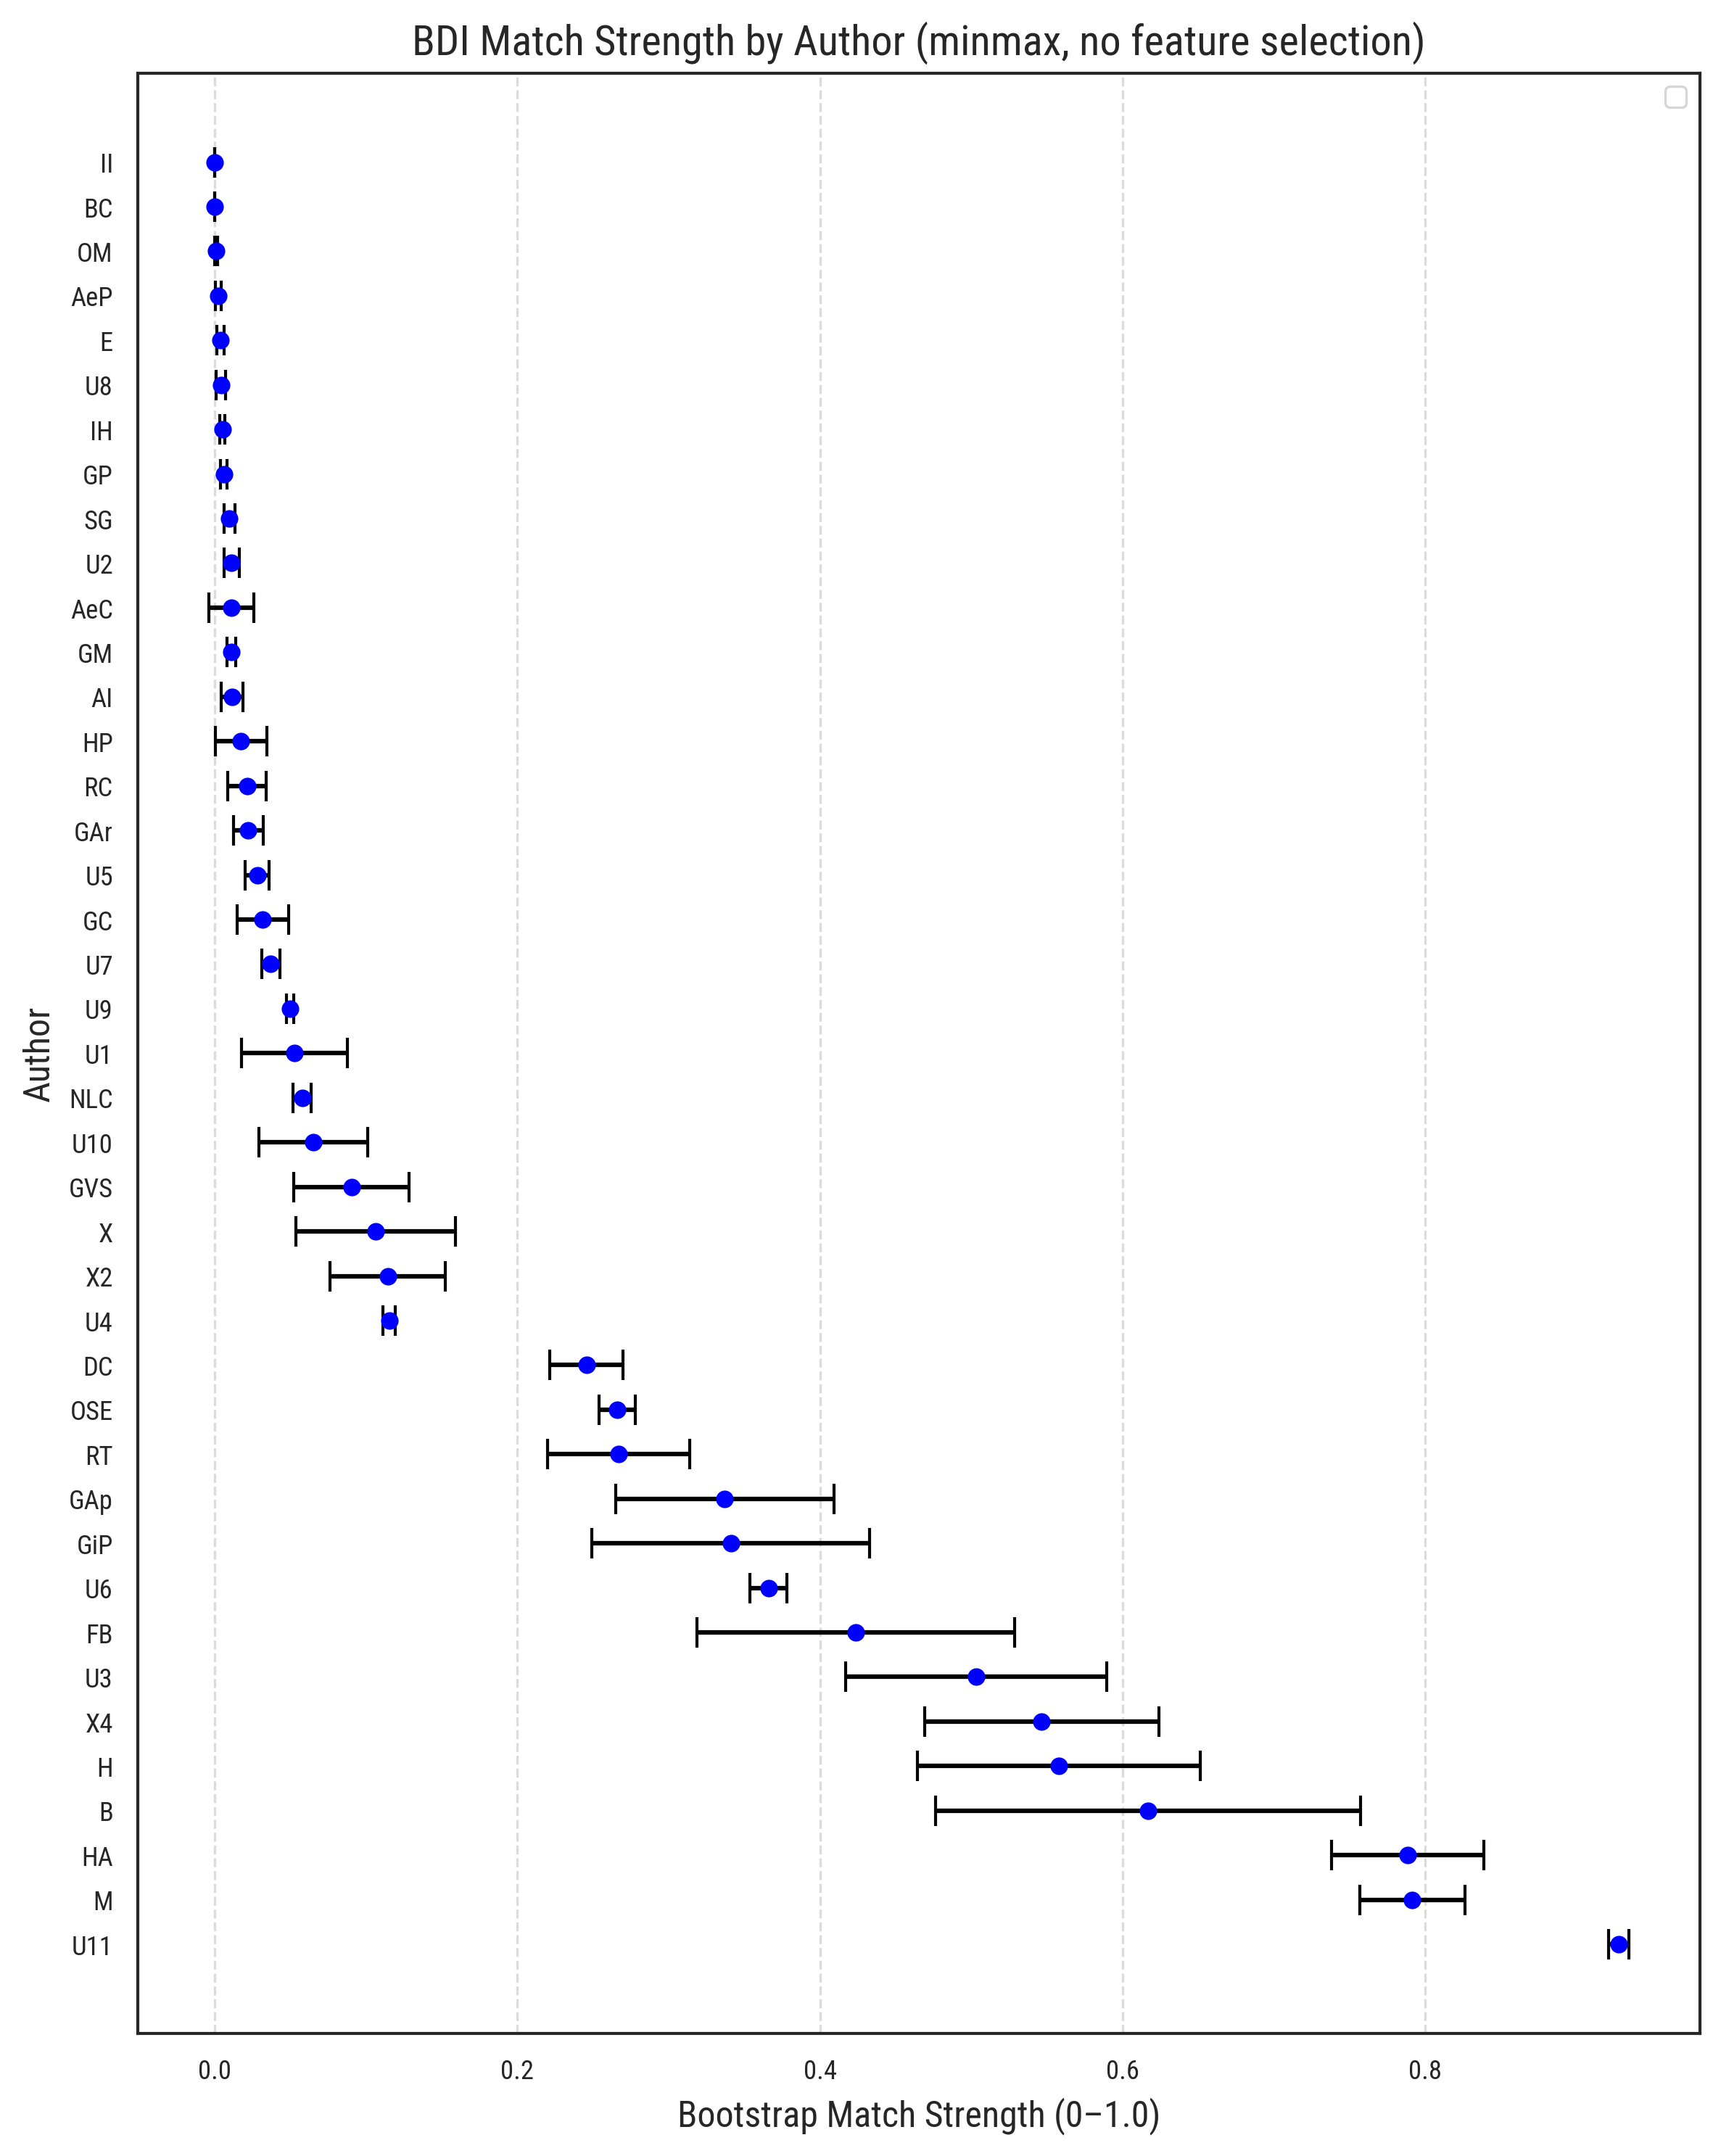

In [61]:
sorted_authors = sorted(results.items(), key=lambda x: x[1]["mean"], reverse=True)

labels_plot = [a[0] for a in sorted_authors]
means = [a[1]["mean"] for a in sorted_authors]
stds = [a[1]["std"] for a in sorted_authors]

fig, ax = plt.subplots(figsize=(8, 10))
ax.errorbar(
    means,
    labels_plot,
    xerr=stds,
    fmt="o",
    color="blue",
    ecolor="black",
    elinewidth=1.5,
    capsize=5,
)
ax.set_xlabel("Bootstrap Match Strength (0–1.0)", fontsize=12)
ax.set_ylabel("Author", fontsize=12)
ax.set_title("BDI Match Strength by Author (minmax, no feature selection)", fontsize=14)
ax.grid(axis="x", linestyle="--", alpha=0.7)
ax.legend()
fig.tight_layout()
plt.savefig("forest_plot_minmax.png", dpi=300, bbox_inches="tight")
plt.show()

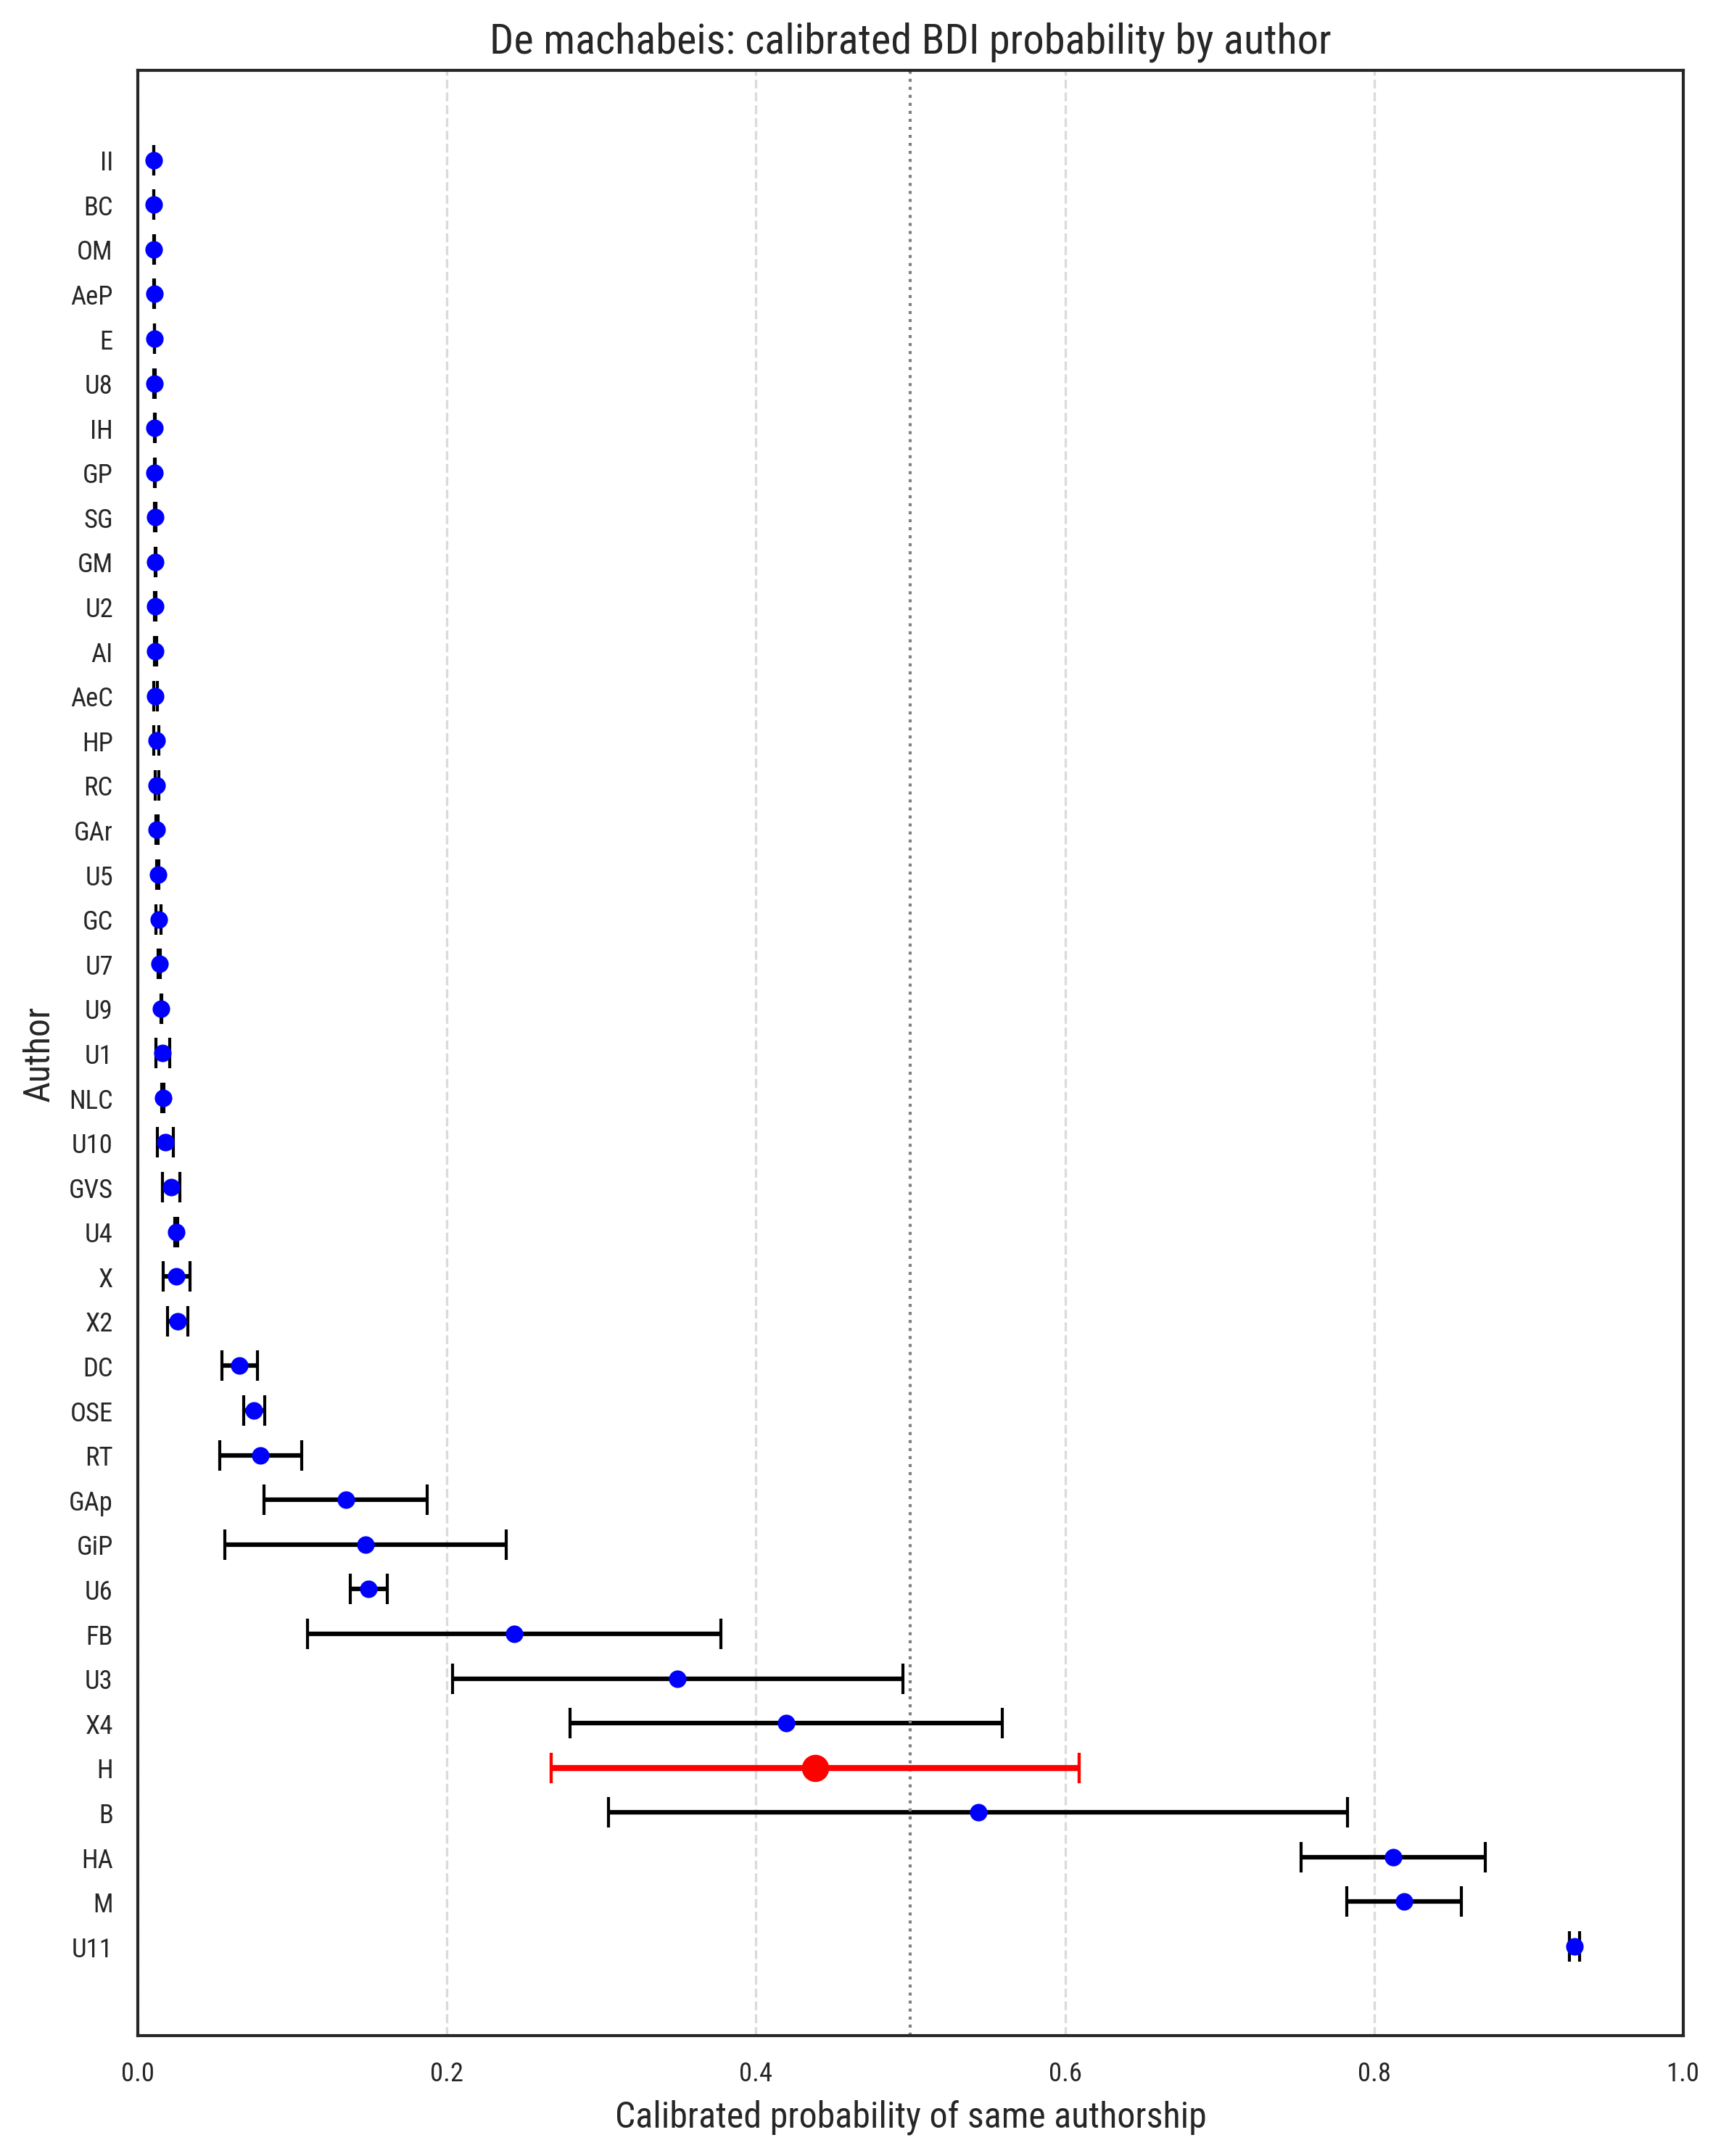

In [62]:
sorted_authors_cal = sorted(
    results.items(),
    key=lambda x: x[1]["calibrated_mean"],
    reverse=True,
)

labels_plot_cal = [a[0] for a in sorted_authors_cal]
means_cal = [a[1]["calibrated_mean"] for a in sorted_authors_cal]
stds_cal = [a[1]["calibrated_std"] for a in sorted_authors_cal]

fig, ax = plt.subplots(figsize=(8, 10))

ax.errorbar(
    means_cal,
    labels_plot_cal,
    xerr=stds_cal,
    fmt="o",
    color="blue",
    ecolor="black",
    elinewidth=1.5,
    capsize=5,
)

if "H" in labels_plot_cal:
    h_idx = labels_plot_cal.index("H")
    ax.errorbar(
        means_cal[h_idx],
        labels_plot_cal[h_idx],
        xerr=stds_cal[h_idx],
        fmt="o",
        color="red",
        ecolor="red",
        elinewidth=2,
        capsize=5,
        markersize=8,
        zorder=5,
    )

ax.axvline(
    0.5,
    color="gray",
    linestyle=":",
    linewidth=1,
)

ax.set_xlabel(
    "Calibrated probability of same authorship",
    fontsize=12,
)
ax.set_ylabel("Author", fontsize=12)
ax.set_title(
    "De machabeis: calibrated BDI probability by author",
    fontsize=14,
)
ax.set_xlim(0, 1)
ax.grid(axis="x", linestyle="--", alpha=0.7)

fig.tight_layout()
plt.savefig(
    "machabeis_forest_plot_calibrated.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

## Ablation analysis

In [64]:
# ============================================================
# ABLATION ANALYSIS
# De Machabeis
#
# 1. Family ablation
# 2. Single-feature ablation
# 3. Joint ablation: 2SP + 3SC
#
# Interpretation of delta:
#
# Positive delta:
# removing the feature(s) lowers the match
# => the feature(s) SUPPORT similarity
#
# Negative delta:
# removing the feature(s) raises the match
# => the feature(s) WORK AGAINST similarity
# ============================================================

import pandas as pd
import numpy as np


# ============================================================
# SETTINGS
# ============================================================

# Candidates of particular interest:
#
# U11 = Passio Katherinae
# M   = Marbodus Redonensis
# X4  = Certamina septem fratrum Machabeorum
# H   = Hildebertus Cenomanensis

candidates_of_interest = ["U11", "M", "X4", "H"]

# Same seeds used in the other ablation experiments
seeds = [11, 22, 33, 44, 55]

# All metrical features actually used by the model
all_features = list(problem_X.columns)

print("Features used in full model:")
print(all_features)
print("Number of features:", len(all_features))


# ============================================================
# CHECK CANDIDATES
# ============================================================

missing_candidates = [
    candidate
    for candidate in candidates_of_interest
    if candidate not in label_encoder.classes_
]

if missing_candidates:
    raise ValueError(
        f"Candidates not found in label_encoder: {missing_candidates}"
    )

print("\nCandidates analysed:")
print(candidates_of_interest)


# ============================================================
# FEATURE FAMILIES
#
# SP  = spondaic feet
# CF  = ictus / word-accent conflict
# DI  = diaeresis
# SC  = strong caesura
# WC  = weak caesura
# ELC = mean elisions per verse
# ============================================================

feature_families = {

    "Spondees": [
        f for f in all_features
        if f.endswith("SP")
    ],

    "Ictus-accent conflict": [
        f for f in all_features
        if f.endswith("CF")
    ],

    "Diaereses": [
        f for f in all_features
        if f.endswith("DI")
    ],

    "Strong caesurae": [
        f for f in all_features
        if f.endswith("SC")
    ],

    "Weak caesurae": [
        f for f in all_features
        if f.endswith("WC")
    ],

    "Elisions": [
        f for f in all_features
        if f == "ELC"
    ],
}


# Remove empty families automatically
feature_families = {
    family: features
    for family, features in feature_families.items()
    if len(features) > 0
}


print("\nFeature families:")

for family, features in feature_families.items():
    print(f"{family}: {features}")


# ============================================================
# CHECK THAT EVERY FEATURE BELONGS TO A FAMILY
# ============================================================

features_in_families = set(
    feature
    for features in feature_families.values()
    for feature in features
)

unassigned_features = [
    feature
    for feature in all_features
    if feature not in features_in_families
]

if unassigned_features:
    print(
        "\nWARNING: the following features are not assigned "
        "to any family:"
    )
    print(unassigned_features)
else:
    print("\nAll features are assigned to a family.")


# ============================================================
# TARGETED JOINT ABLATION
#
# 2SP = spondee in the second foot
# 3SC = strong caesura in the third foot
#       (penthemimeral caesura)
#
# These two features are removed jointly to test whether
# similarity depends strongly on two traits that may be
# associated with leonine verse structure.
# ============================================================

joint_features = ["2SP", "3SC"]

missing_joint_features = [
    feature
    for feature in joint_features
    if feature not in all_features
]

if missing_joint_features:
    raise ValueError(
        f"Joint-ablation features not found: {missing_joint_features}"
    )


# ============================================================
# HELPER:
# CONVERT CANDIDATE STRING LABEL TO ENCODED LABEL
# ============================================================

def get_encoded_label(candidate):

    matches = np.where(
        label_encoder.classes_ == candidate
    )[0]

    if len(matches) != 1:
        raise ValueError(
            f"Could not uniquely identify candidate {candidate}"
        )

    return int(matches[0])


# ============================================================
# HELPER:
# RUN BDI FOR SELECTED CANDIDATES
# ============================================================

def run_bdi_selected(features, seed=42):

    rng = np.random.default_rng(seed)

    verifier = BDIVerifier(
        metric="minmax",
        nb_bootstrap_iter=1000,
        rnd_prop=0.5,
        random_state=rng,
    )

    verifier.fit(
        comparison_X[features],
        comparison_y
    )

    results = {}

    for candidate in candidates_of_interest:

        int_label = get_encoded_label(candidate)

        scores = verifier.predict_proba(
            problem_X[features],
            [int_label] * problem_X.shape[0],
        )

        scores = np.asarray(
            scores,
            dtype=float
        )

        results[candidate] = {
            "mean": scores.mean(),
            "std_chunks": scores.std(),
            "chunks": scores.copy(),
        }

    return results


# ============================================================
# HELPER:
# AGGREGATE RESULTS ACROSS SEEDS
# ============================================================

def aggregate_ablation(df, group_columns):

    summary = (
        df
        .groupby(
            group_columns,
            as_index=False
        )
        .agg(
            baseline_mean=(
                "Baseline match",
                "mean"
            ),
            ablated_mean=(
                "Ablated match",
                "mean"
            ),
            delta_mean=(
                "Delta",
                "mean"
            ),
            delta_std=(
                "Delta",
                "std"
            ),
            delta_min=(
                "Delta",
                "min"
            ),
            delta_max=(
                "Delta",
                "max"
            ),
        )
    )

    direction = (
        df
        .groupby(group_columns)
        ["Delta"]
        .agg(
            positive_fraction=lambda x: (
                x > 0
            ).mean(),
            negative_fraction=lambda x: (
                x < 0
            ).mean(),
        )
        .reset_index()
    )

    summary = summary.merge(
        direction,
        on=group_columns,
        how="left"
    )

    return summary


# ============================================================
# STORAGE
# ============================================================

family_rows = []
single_rows = []
joint_rows = []


# ============================================================
# RUN ALL ABLATION ANALYSES
# ============================================================

for seed in seeds:

    print(f"\n===== SEED {seed} =====")


    # --------------------------------------------------------
    # BASELINE
    # Full model
    # --------------------------------------------------------

    baseline = run_bdi_selected(
        all_features,
        seed=seed
    )


    # --------------------------------------------------------
    # 1. FAMILY ABLATION
    # --------------------------------------------------------

    for family_name, removed_features in feature_families.items():

        retained_features = [
            feature
            for feature in all_features
            if feature not in removed_features
        ]

        ablated = run_bdi_selected(
            retained_features,
            seed=seed
        )

        for candidate in candidates_of_interest:

            baseline_match = baseline[candidate]["mean"]
            ablated_match = ablated[candidate]["mean"]

            delta = baseline_match - ablated_match

            family_rows.append({
                "Seed": seed,
                "Candidate": candidate,
                "Family": family_name,
                "Baseline match": baseline_match,
                "Ablated match": ablated_match,
                "Delta": delta,
            })


    # --------------------------------------------------------
    # 2. SINGLE-FEATURE ABLATION
    # --------------------------------------------------------

    for removed_feature in all_features:

        retained_features = [
            feature
            for feature in all_features
            if feature != removed_feature
        ]

        ablated = run_bdi_selected(
            retained_features,
            seed=seed
        )

        for candidate in candidates_of_interest:

            baseline_match = baseline[candidate]["mean"]
            ablated_match = ablated[candidate]["mean"]

            delta = baseline_match - ablated_match

            single_rows.append({
                "Seed": seed,
                "Candidate": candidate,
                "Feature": removed_feature,
                "Baseline match": baseline_match,
                "Ablated match": ablated_match,
                "Delta": delta,
            })


    # --------------------------------------------------------
    # 3. JOINT ABLATION: 2SP + 3SC
    # --------------------------------------------------------

    retained_features = [
        feature
        for feature in all_features
        if feature not in joint_features
    ]

    ablated = run_bdi_selected(
        retained_features,
        seed=seed
    )

    for candidate in candidates_of_interest:

        baseline_match = baseline[candidate]["mean"]
        ablated_match = ablated[candidate]["mean"]

        delta = baseline_match - ablated_match

        joint_rows.append({
            "Seed": seed,
            "Candidate": candidate,
            "Removed features": "2SP + 3SC",
            "Baseline match": baseline_match,
            "Ablated match": ablated_match,
            "Delta": delta,
        })


# ============================================================
# CREATE DATAFRAMES
# ============================================================

family_raw = pd.DataFrame(family_rows)
single_raw = pd.DataFrame(single_rows)
joint_raw = pd.DataFrame(joint_rows)


# ============================================================
# AGGREGATE RESULTS
# ============================================================

family_summary = aggregate_ablation(
    family_raw,
    ["Candidate", "Family"]
)

single_summary = aggregate_ablation(
    single_raw,
    ["Candidate", "Feature"]
)

joint_summary = aggregate_ablation(
    joint_raw,
    ["Candidate", "Removed features"]
)


# ============================================================
# CANDIDATE ORDER
# ============================================================

for df in [
    family_summary,
    single_summary,
    joint_summary
]:

    df["Candidate"] = pd.Categorical(
        df["Candidate"],
        categories=candidates_of_interest,
        ordered=True
    )


# ============================================================
# TABLE 1
# FAMILY ABLATION
# ============================================================

family_order = list(
    feature_families.keys()
)

family_summary["Family"] = pd.Categorical(
    family_summary["Family"],
    categories=family_order,
    ordered=True
)

family_summary = (
    family_summary
    .sort_values(
        ["Candidate", "Family"]
    )
    .reset_index(drop=True)
)

family_delta_matrix = (
    family_summary
    .pivot(
        index="Family",
        columns="Candidate",
        values="delta_mean"
    )
    .reindex(family_order)
    [candidates_of_interest]
)


print("\n\n")
print("=" * 76)
print("TABLE 1 — FAMILY ABLATION")
print("=" * 76)

print(
    "\nPositive value = family supports similarity"
)

print(
    "Negative value = family works against similarity"
)

display(
    family_delta_matrix.round(4)
)


# ============================================================
# TABLE 2
# SINGLE-FEATURE ABLATION
# ============================================================

preferred_order = [
    "1SP", "2SP", "3SP", "4SP",
    "1CF", "2CF", "3CF", "4CF",
    "1DI", "2DI", "3DI", "4DI",
    "1SC", "2SC", "3SC", "4SC",
    "1WC", "2WC", "3WC", "4WC",
    "ELC",
]

preferred_order = [
    feature
    for feature in preferred_order
    if feature in all_features
]

remaining_features = [
    feature
    for feature in all_features
    if feature not in preferred_order
]

preferred_order += remaining_features


single_delta_matrix = (
    single_summary
    .pivot(
        index="Feature",
        columns="Candidate",
        values="delta_mean"
    )
    .reindex(preferred_order)
    [candidates_of_interest]
)


print("\n\n")
print("=" * 76)
print("TABLE 2 — SINGLE-FEATURE ABLATION")
print("=" * 76)

print(
    "\nPositive value = feature supports similarity"
)

print(
    "Negative value = feature works against similarity"
)

display(
    single_delta_matrix.round(4)
)


# ============================================================
# TABLE 3
# JOINT ABLATION: 2SP + 3SC
# ============================================================

joint_summary = (
    joint_summary
    .sort_values("Candidate")
    .reset_index(drop=True)
)

joint_table = joint_summary[
    [
        "Candidate",
        "baseline_mean",
        "ablated_mean",
        "delta_mean",
        "delta_std",
        "positive_fraction",
        "negative_fraction",
    ]
].copy()

joint_table.columns = [
    "Candidate",
    "Baseline",
    "Without 2SP + 3SC",
    "Delta",
    "Delta SD",
    "Positive fraction",
    "Negative fraction",
]


print("\n\n")
print("=" * 76)
print("TABLE 3 — JOINT ABLATION: 2SP + 3SC")
print("=" * 76)

print(
    "\n2SP = spondee in the second foot"
)

print(
    "3SC = strong caesura in the third foot "
    "(penthemimeral caesura)"
)

print(
    "\nPositive delta = the two features jointly support similarity"
)

print(
    "Negative delta = the two features jointly work against similarity"
)

display(
    joint_table.round(4)
)


# ============================================================
# TABLE 4
# DETAILED SINGLE-FEATURE RESULTS BY CANDIDATE
# ============================================================

for candidate in candidates_of_interest:

    print(
        f"\n\n===== SINGLE FEATURES: {candidate} ====="
    )

    candidate_table = (
        single_summary[
            single_summary["Candidate"]
            == candidate
        ]
        .set_index("Feature")
        .reindex(preferred_order)
        .reset_index()
        [
            [
                "Feature",
                "baseline_mean",
                "ablated_mean",
                "delta_mean",
                "delta_std",
                "positive_fraction",
                "negative_fraction",
            ]
        ]
    )

    display(
        candidate_table.round(4)
    )


# ============================================================
# TABLE 5
# LARGEST SINGLE-FEATURE EFFECTS BY CANDIDATE
# ============================================================

for candidate in candidates_of_interest:

    print(
        f"\n\n===== LARGEST EFFECTS: {candidate} ====="
    )

    ranked = (
        single_summary[
            single_summary["Candidate"]
            == candidate
        ]
        .copy()
    )

    ranked["abs_delta"] = ranked["delta_mean"].abs()

    ranked = (
        ranked
        .sort_values(
            "abs_delta",
            ascending=False
        )
        [
            [
                "Feature",
                "baseline_mean",
                "ablated_mean",
                "delta_mean",
                "delta_std",
                "positive_fraction",
                "negative_fraction",
            ]
        ]
    )

    display(
        ranked.head(10).round(4)
    )


# ============================================================
# SAVE RESULTS
# ============================================================

family_raw.to_csv(
    "machabeis_family_ablation_raw.csv",
    index=False
)

family_summary.to_csv(
    "machabeis_family_ablation_summary.csv",
    index=False
)

family_delta_matrix.to_csv(
    "machabeis_family_ablation_deltas.csv"
)

single_raw.to_csv(
    "machabeis_single_feature_ablation_raw.csv",
    index=False
)

single_summary.to_csv(
    "machabeis_single_feature_ablation_summary.csv",
    index=False
)

single_delta_matrix.to_csv(
    "machabeis_single_feature_ablation_deltas.csv"
)

joint_raw.to_csv(
    "machabeis_joint_ablation_2SP_3SC_raw.csv",
    index=False
)

joint_summary.to_csv(
    "machabeis_joint_ablation_2SP_3SC_summary.csv",
    index=False
)


# ============================================================
# DONE
# ============================================================

print("\n")
print("=" * 76)
print("DONE")
print("=" * 76)

print(
    "\nSaved family, single-feature, "
    "and joint-ablation results for De Machabeis."
)

09/18/2026 07:07:52 [bdi:INFO] Fitting on 660 documents...
09/18/2026 07:07:52 [bdi:INFO] Predicting on 3 documents
09/18/2026 07:07:52 [bdi:INFO] Predicting on 3 documents


Features used in full model:
['1SP', '2SP', '3SP', '4SP', '1CF', '2CF', '3CF', '4CF', '1DI', '2DI', '3DI', '4DI', '1SC', '2SC', '3SC', '4SC', '1WC', '2WC', '3WC', '4WC', 'ELC']
Number of features: 21

Candidates analysed:
['U11', 'M', 'X4', 'H']

Feature families:
Spondees: ['1SP', '2SP', '3SP', '4SP']
Ictus-accent conflict: ['1CF', '2CF', '3CF', '4CF']
Diaereses: ['1DI', '2DI', '3DI', '4DI']
Strong caesurae: ['1SC', '2SC', '3SC', '4SC']
Weak caesurae: ['1WC', '2WC', '3WC', '4WC']
Elisions: ['ELC']

All features are assigned to a family.

===== SEED 11 =====


09/18/2026 07:07:53 [bdi:INFO] Predicting on 3 documents
09/18/2026 07:07:53 [bdi:INFO] Predicting on 3 documents
09/18/2026 07:07:53 [bdi:INFO] Fitting on 660 documents...
09/18/2026 07:07:53 [bdi:INFO] Predicting on 3 documents
09/18/2026 07:07:53 [bdi:INFO] Predicting on 3 documents
09/18/2026 07:07:53 [bdi:INFO] Predicting on 3 documents
09/18/2026 07:07:53 [bdi:INFO] Predicting on 3 documents
09/18/2026 07:07:53 [bdi:INFO] Fitting on 660 documents...
09/18/2026 07:07:53 [bdi:INFO] Predicting on 3 documents
09/18/2026 07:07:53 [bdi:INFO] Predicting on 3 documents
09/18/2026 07:07:53 [bdi:INFO] Predicting on 3 documents
09/18/2026 07:07:53 [bdi:INFO] Predicting on 3 documents
09/18/2026 07:07:53 [bdi:INFO] Fitting on 660 documents...
09/18/2026 07:07:53 [bdi:INFO] Predicting on 3 documents
09/18/2026 07:07:54 [bdi:INFO] Predicting on 3 documents
09/18/2026 07:07:54 [bdi:INFO] Predicting on 3 documents
09/18/2026 07:07:54 [bdi:INFO] Predicting on 3 documents
09/18/2026 07:07:54 [bdi:


===== SEED 22 =====


09/18/2026 07:08:04 [bdi:INFO] Predicting on 3 documents
09/18/2026 07:08:04 [bdi:INFO] Predicting on 3 documents
09/18/2026 07:08:04 [bdi:INFO] Fitting on 660 documents...
09/18/2026 07:08:04 [bdi:INFO] Predicting on 3 documents
09/18/2026 07:08:04 [bdi:INFO] Predicting on 3 documents
09/18/2026 07:08:04 [bdi:INFO] Predicting on 3 documents
09/18/2026 07:08:04 [bdi:INFO] Predicting on 3 documents
09/18/2026 07:08:04 [bdi:INFO] Fitting on 660 documents...
09/18/2026 07:08:04 [bdi:INFO] Predicting on 3 documents
09/18/2026 07:08:04 [bdi:INFO] Predicting on 3 documents
09/18/2026 07:08:04 [bdi:INFO] Predicting on 3 documents
09/18/2026 07:08:04 [bdi:INFO] Predicting on 3 documents
09/18/2026 07:08:04 [bdi:INFO] Fitting on 660 documents...
09/18/2026 07:08:04 [bdi:INFO] Predicting on 3 documents
09/18/2026 07:08:05 [bdi:INFO] Predicting on 3 documents
09/18/2026 07:08:05 [bdi:INFO] Predicting on 3 documents
09/18/2026 07:08:05 [bdi:INFO] Predicting on 3 documents
09/18/2026 07:08:05 [bdi:

...



===== LARGEST EFFECTS: X4 =====


,Feature,baseline_mean,ablated_mean,delta_mean,delta_std,positive_fraction,negative_fraction
76,3SP,0.6478,0.7747,-0.1269,0.0035,0.0,1.0
82,4WC,0.6478,0.7281,-0.0803,0.0089,0.0,1.0
67,1WC,0.6478,0.5711,0.0767,0.0105,1.0,0.0
66,1SP,0.6478,0.5831,0.0647,0.0081,1.0,0.0
68,2CF,0.6478,0.7026,-0.0548,0.0032,0.0,1.0
65,1SC,0.6478,0.6005,0.0473,0.0086,1.0,0.0
72,2WC,0.6478,0.6121,0.0357,0.0096,1.0,0.0
64,1DI,0.6478,0.6177,0.0301,0.0096,1.0,0.0
79,4DI,0.6478,0.6245,0.0233,0.0065,1.0,0.0
70,2SC,0.6478,0.6690,-0.0212,0.0073,0.0,1.0




===== LARGEST EFFECTS: H =====


,Feature,baseline_mean,ablated_mean,delta_mean,delta_std,positive_fraction,negative_fraction
8,2SP,0.6303,0.5421,0.0881,0.0081,1.0,0.0
16,4DI,0.6303,0.7128,-0.0825,0.0057,0.0,1.0
18,4SP,0.6303,0.5506,0.0797,0.0092,1.0,0.0
13,3SP,0.6303,0.5786,0.0517,0.0089,1.0,0.0
9,2WC,0.6303,0.6814,-0.0511,0.0129,0.0,1.0
0,1CF,0.6303,0.6722,-0.0419,0.0053,0.0,1.0
4,1WC,0.6303,0.6655,-0.0353,0.0077,0.0,1.0
1,1DI,0.6303,0.6000,0.0303,0.0068,1.0,0.0
7,2SC,0.6303,0.6586,-0.0283,0.0062,0.0,1.0
19,4WC,0.6303,0.6567,-0.0264,0.0148,0.0,1.0




DONE

Saved family, single-feature, and joint-ablation results for De Machabeis.


## Interpretation

The raw BDI match strength is retained as the direct output of the verifier. At the application stage, other uncertain texts may also serve as comparison candidates; they were excluded only from calibration. Its corpus-specific interpretation is provided by the logistic calibration estimated on known-author cases in `2. evaluate_calibrate_metric_hexameters.ipynb`.

`Calibrated Probability` is the logistic transformation of each segment-level BDI match strength. Values closer to 1 are more compatible with the known same-author calibration cases; values closer to 0 are more compatible with the different-author cases.

## Chunked Visualization

We can inspect the full bootstrap distance distribution per chunk using `_dist_arrays`. This shows the uncertainty in our determinations.


### Candidate: Hildebert (H)

In [67]:
label_index_H = label_encoder.transform(["H"])[0]

bdi_mm.predict_proba(
    problem_X,
    [label_index_H] * problem_X.shape[0],
)

machabeis_vs_hildebert = pd.DataFrame(
    dict(zip(raw_df.loc[problem_mask].index, bdi_mm._dist_arrays))
)
machabeis_vs_hildebert

09/18/2026 07:08:48 [bdi:INFO] Predicting on 3 documents


,656,657,658
0,-0.030984,0.060302,-0.026497
1,0.028812,-0.012746,-0.017169
2,-0.015792,-0.020892,0.111600
3,-0.054940,0.013103,0.001422
4,-0.060347,0.038011,-0.021167
...,...,...,...
995,-0.009320,-0.022711,-0.062883
996,-0.051491,-0.037516,-0.052772
997,-0.060525,-0.041003,0.033778
998,-0.027113,0.050086,-0.066862


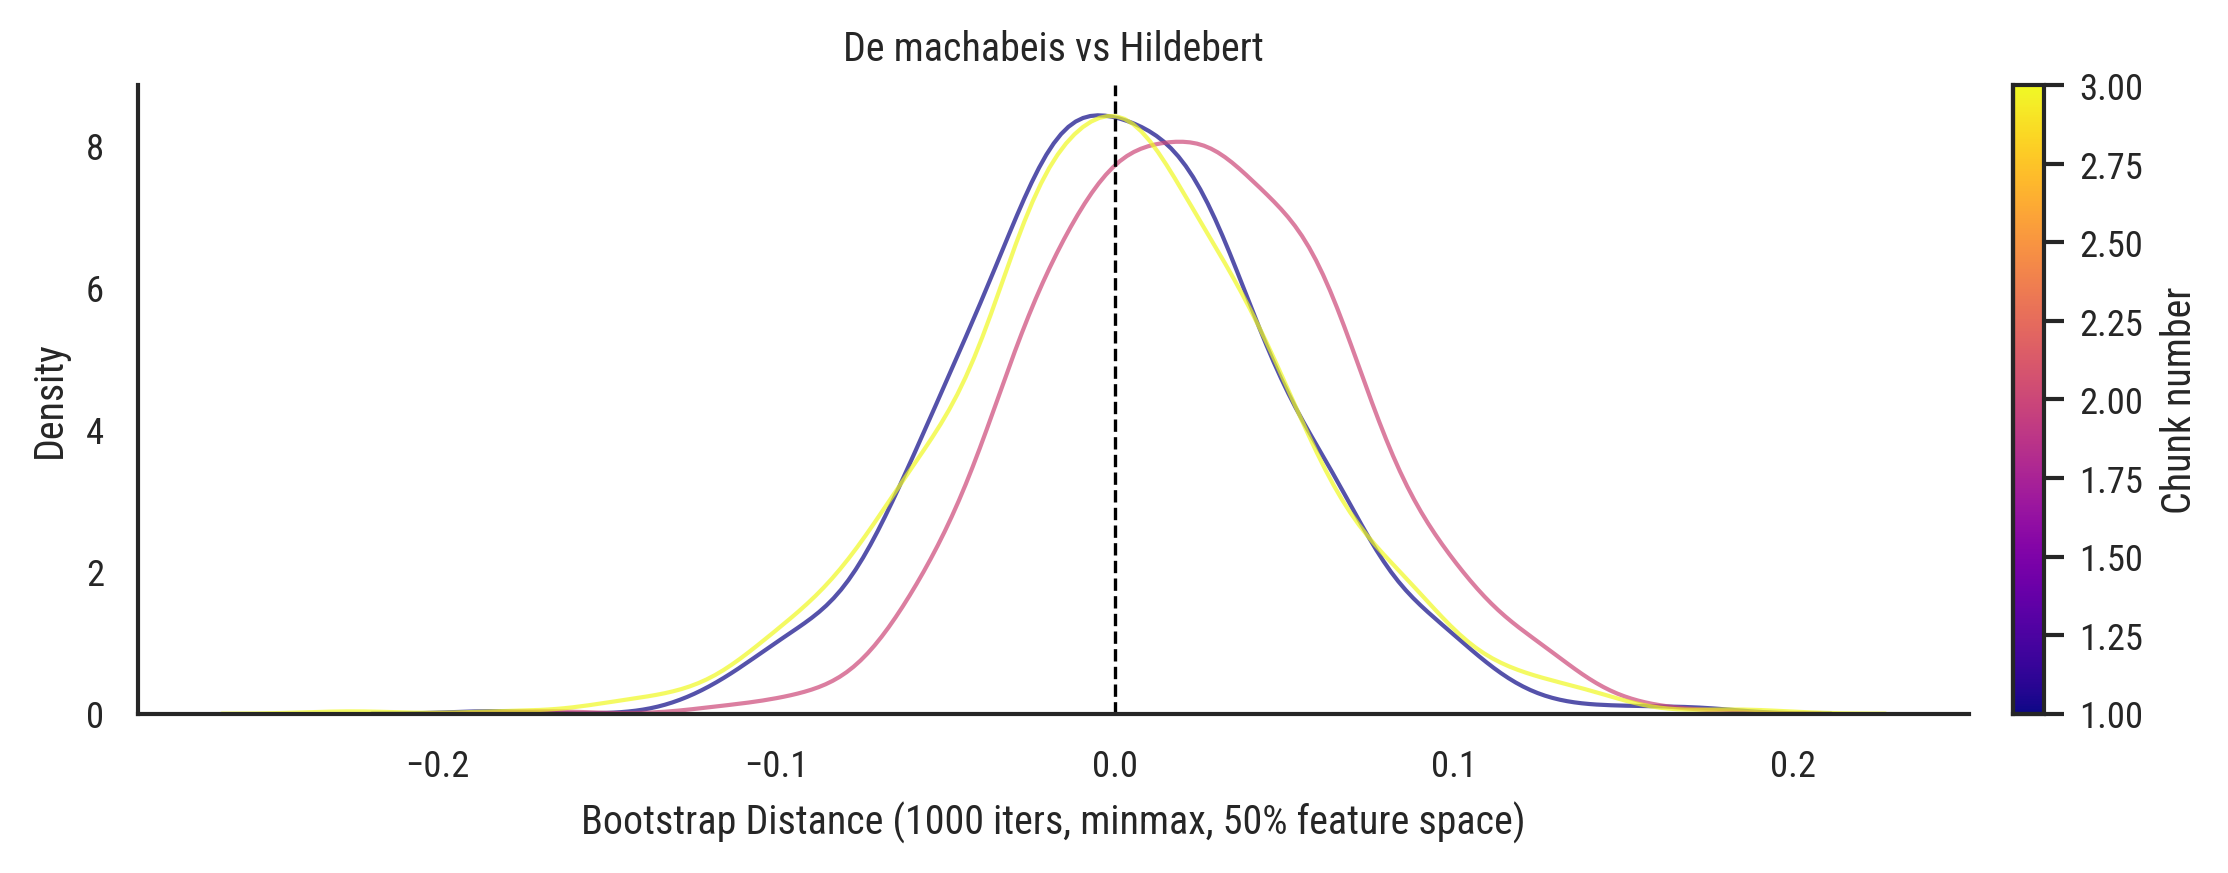

In [68]:
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import re


def plot_kde_viridis(dist_df, poem_names, title="", xlabel="", ax=None):
    """Plot KDE curves colored by chunk number using viridis plasma.

    Later chunks (higher number in poem name) get darker colors.
    """
    # Extract chunk numbers from poem names like "librosregum - 1", "librosregum - 2"
    chunk_nums = []
    for idx in dist_df.columns:
        name = poem_names.loc[idx, "Poem"] if idx in poem_names.index else str(idx)
        m = re.search(r"(\d+)", name)
        chunk_nums.append(int(m.group(1)) if m else 0)

    chunk_nums = np.array(chunk_nums)
    n_chunks = len(chunk_nums)

    # Normalize chunk numbers to [0, 1] for colormap
    if chunk_nums.max() > chunk_nums.min():
        norm_vals = (chunk_nums - chunk_nums.min()) / (
            chunk_nums.max() - chunk_nums.min()
        )
    else:
        norm_vals = np.ones(n_chunks) * 0.5

    # Plasma: low values = bright/yellow, high values = dark/purple
    cmap = cm.plasma
    colors = [cmap(v) for v in norm_vals]

    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 3))

    for col, color in zip(dist_df.columns, colors):
        sns.kdeplot(dist_df[col], color=color, linewidth=1, alpha=0.7, ax=ax)

    ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
    ax.set(xlabel=xlabel, ylabel="Density", title=title)

    # Add colorbar as legend
    sm = cm.ScalarMappable(
        cmap=cmap, norm=mcolors.Normalize(vmin=chunk_nums.min(), vmax=chunk_nums.max())
    )
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax, pad=0.02)
    cbar.set_label("Chunk number")

    return ax


poem_names = raw_df.loc[problem_mask]

sns.set_theme(
    context="paper",
    font="Roboto Condensed",
    style="white",
    rc={"figure.figsize": (8, 3), "figure.dpi": 300},
)
fig, ax = plt.subplots(figsize=(8, 3))
plot_kde_viridis(
    machabeis_vs_hildebert,
    poem_names,
    title="De machabeis vs Hildebert",
    xlabel="Bootstrap Distance (1000 iters, minmax, 50% feature space)",
    ax=ax,
)
sns.despine()
fig.tight_layout()
plt.show()

NOTE: BDI match strengths favour precision and should not be interpreted directly as probabilities. The calibrated probabilities reported above are obtained from the corpus-specific logistic calibration on known-author cases.

## Additional Candidates

We test several alternative known-author candidates to compare their bootstrap distance distributions.


09/18/2026 07:08:48 [bdi:INFO] Predicting on 3 documents


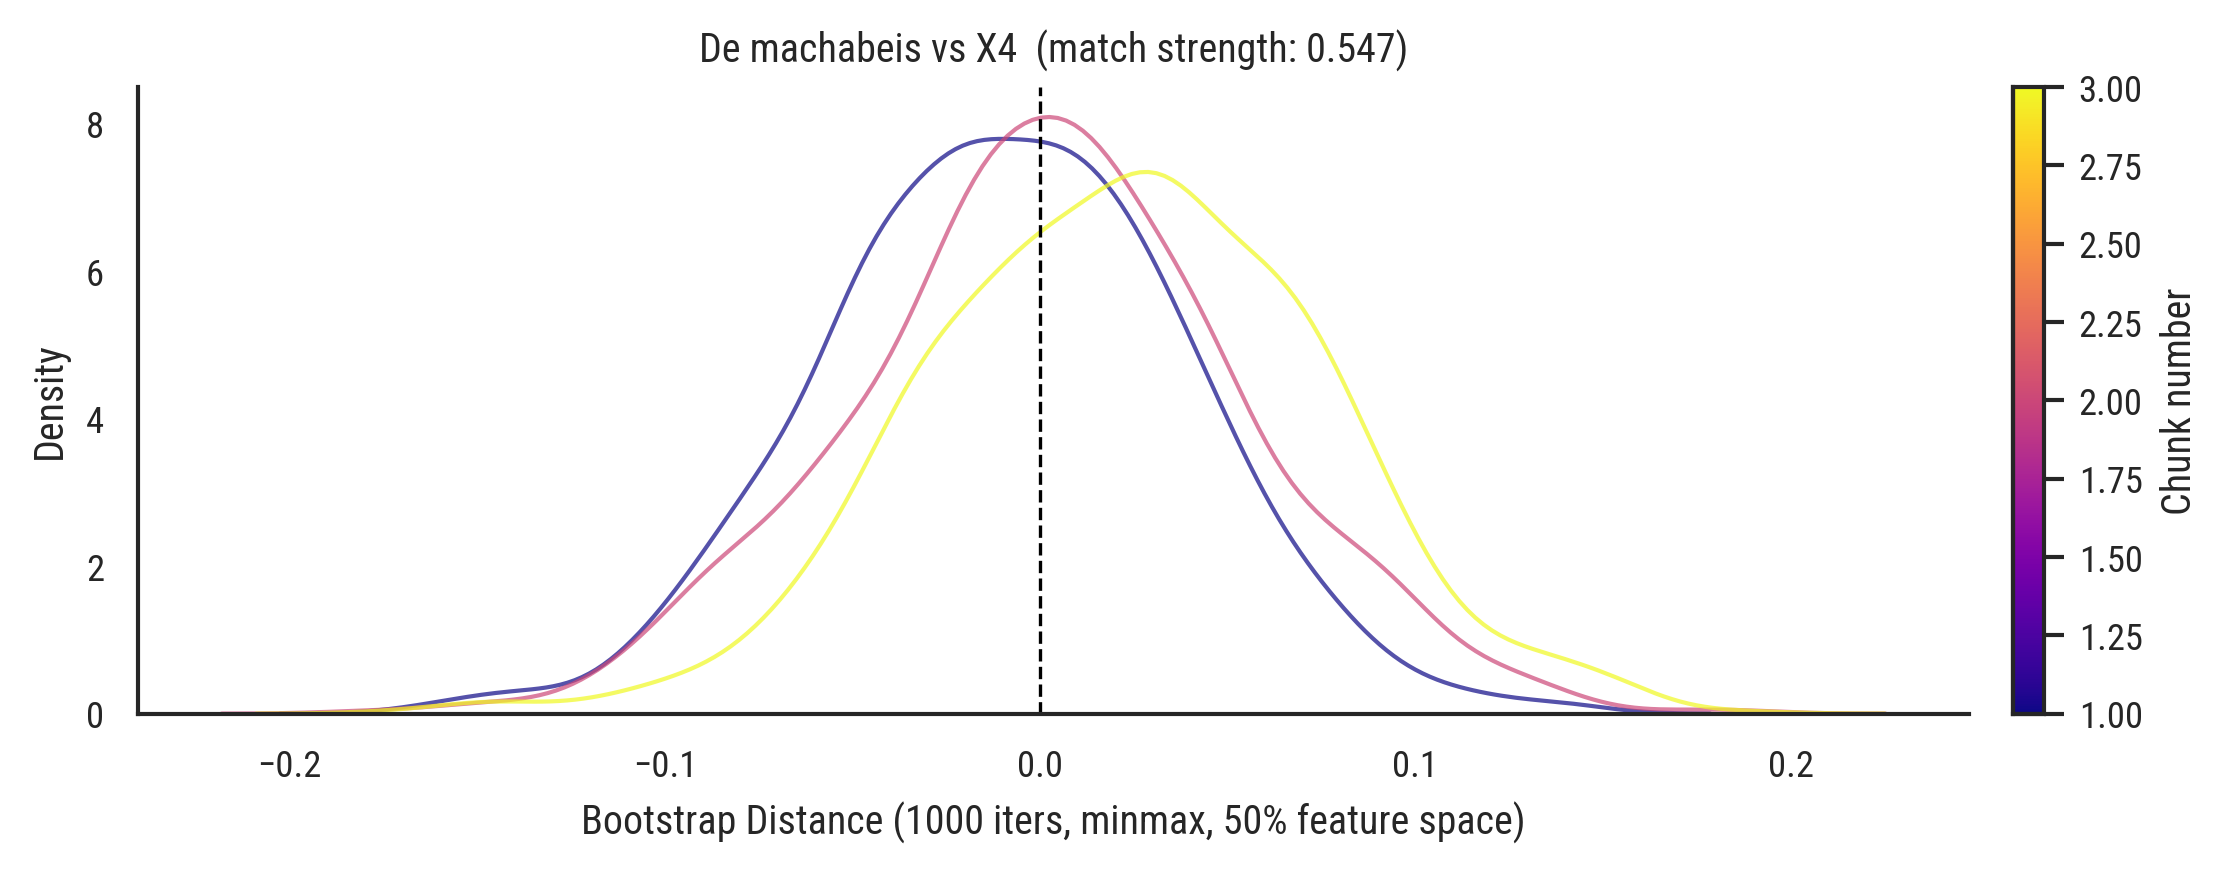

09/18/2026 07:08:49 [bdi:INFO] Predicting on 3 documents


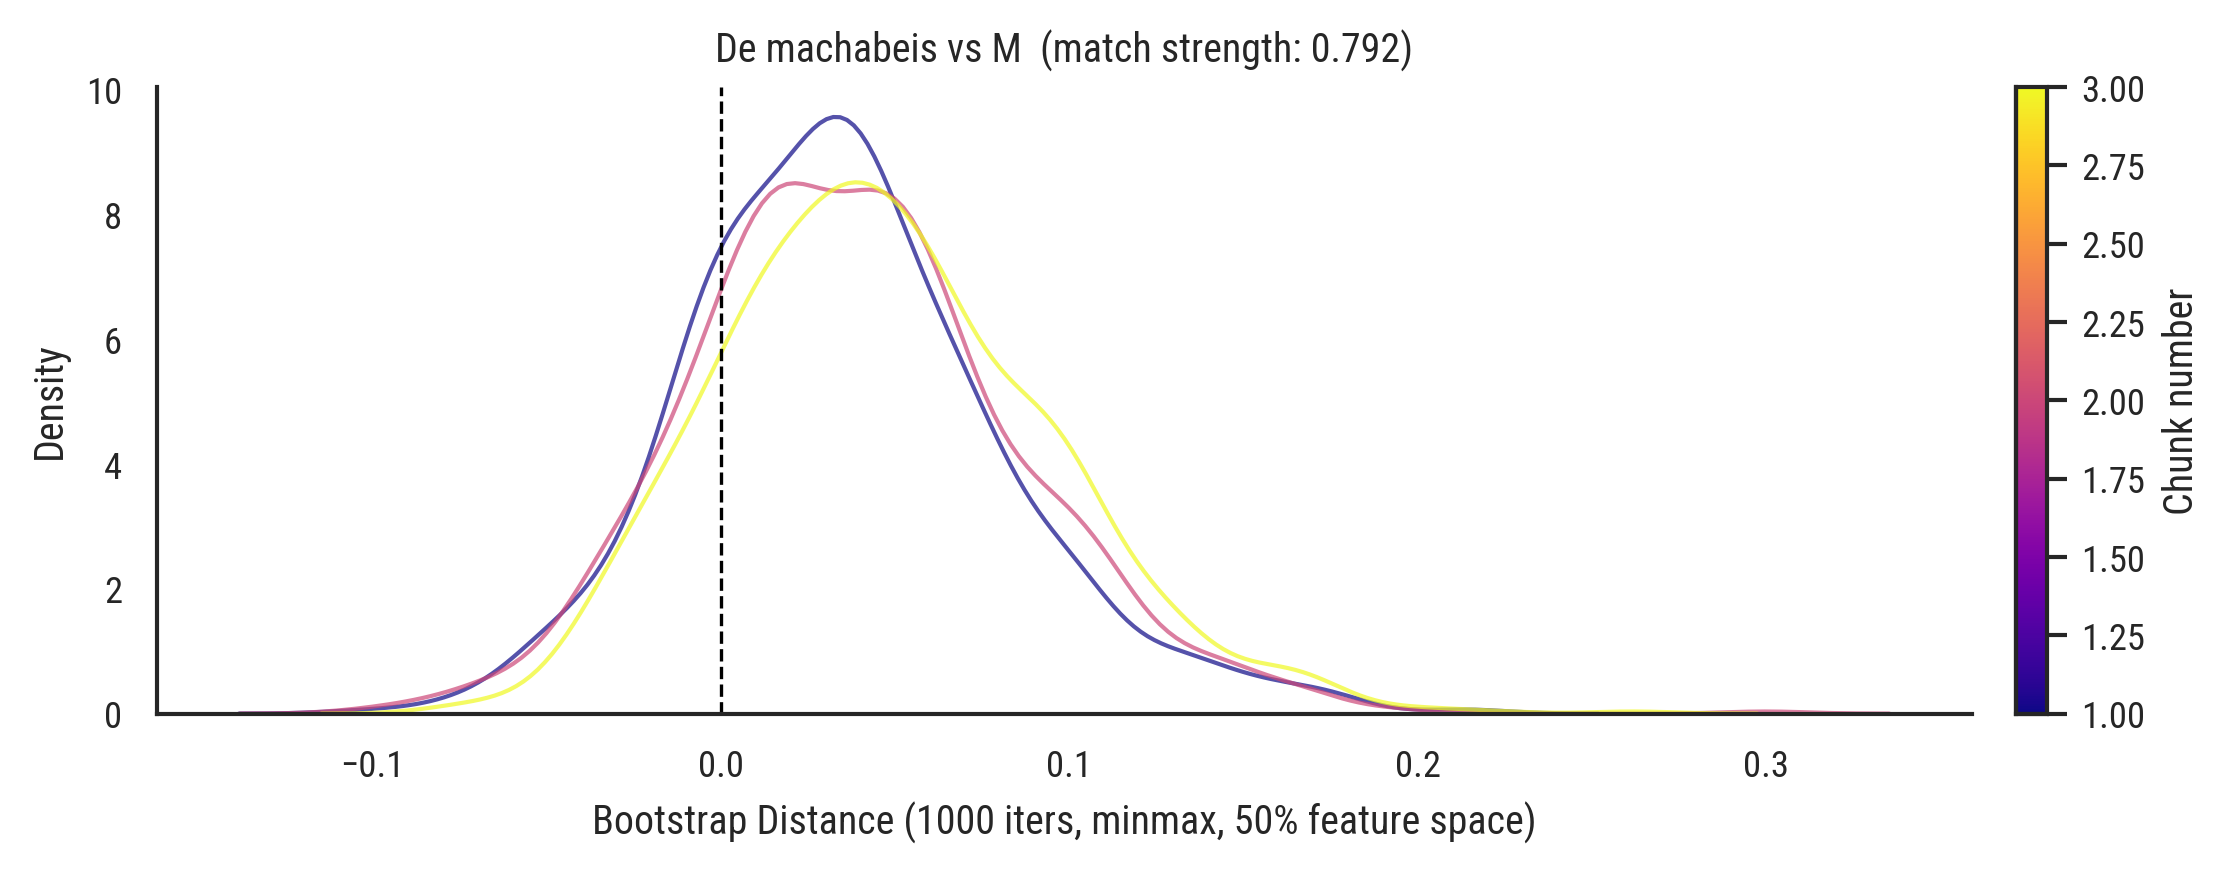

09/18/2026 07:08:49 [bdi:INFO] Predicting on 3 documents


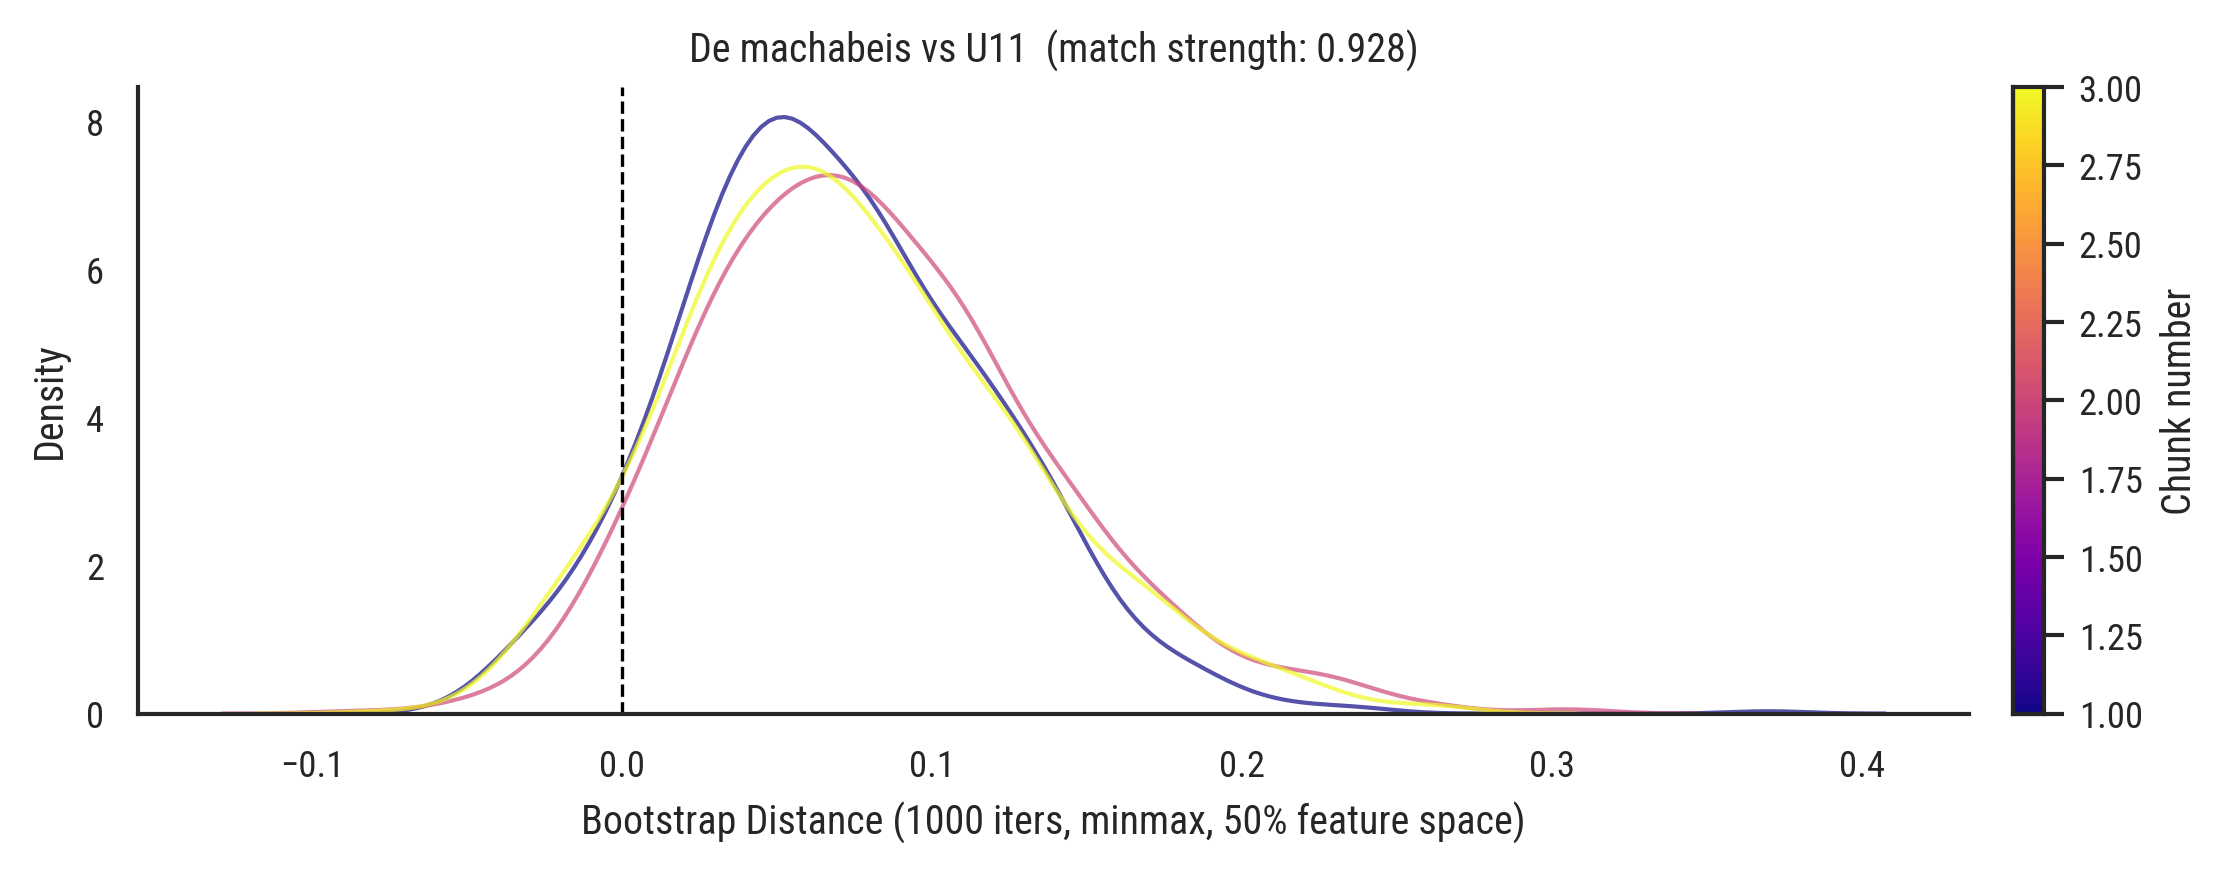

In [70]:
candidates = ['X4', 'M', 'U11']

sns.set_theme(
    context="paper",
    font="Roboto Condensed",
    style="white",
    rc={"figure.figsize": (8, 3), "figure.dpi": 300},
)

for candidate in candidates:
    label_idx = label_encoder.transform([candidate])[0]
    bdi_mm.predict_proba(
        problem_X,
        [label_idx] * problem_X.shape[0],
    )

    dist_df = pd.DataFrame(
        dict(zip(raw_df.loc[problem_mask].index, bdi_mm._dist_arrays))
    )

    mean_str = results[candidate]["mean"]
    fig, ax = plt.subplots(figsize=(8, 3))
    plot_kde_viridis(
        dist_df,
        poem_names,
        title=f"De machabeis vs {candidate}  (match strength: {mean_str:.3f})",
        xlabel="Bootstrap Distance (1000 iters, minmax, 50% feature space)",
        ax=ax,
    )
    sns.despine()
    fig.tight_layout()
    plt.show()